In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
data = pd.DataFrame({
    'Resume': [
        'Python machine learning pandas numpy data analysis',
        'Python developer Django Flask API programming',
        'Machine learning deep learning Python TensorFlow',
        
        'HTML CSS JavaScript React frontend web development',
        'Web developer HTML CSS JavaScript Bootstrap',
        'React JavaScript Node.js frontend developer',
        
        'Java Spring Boot Hibernate SQL backend development',
        'Java developer Spring framework JDBC SQL',
        'Core Java OOP Spring Boot developer',
        
        'Python Django Flask programming developer',
        'Python automation scripting Django developer',
        'Python NumPy Pandas machine learning'
    ],
    
    'Category': [
        'Data Science',
        'Python Developer',
        'Data Science',
        
        'Web Development',
        'Web Development',
        'Web Development',
        
        'Java Developer',
        'Java Developer',
        'Java Developer',
        
        'Python Developer',
        'Python Developer',
        'Data Science'
    ]
})

data

,Resume,Category
0,Python machine learning pandas numpy data anal...,Data Science
1,Python developer Django Flask API programming,Python Developer
2,Machine learning deep learning Python TensorFlow,Data Science
3,HTML CSS JavaScript React frontend web develop...,Web Development
4,Web developer HTML CSS JavaScript Bootstrap,Web Development
5,React JavaScript Node.js frontend developer,Web Development
6,Java Spring Boot Hibernate SQL backend develop...,Java Developer
7,Java developer Spring framework JDBC SQL,Java Developer
8,Core Java OOP Spring Boot developer,Java Developer
9,Python Django Flask programming developer,Python Developer


In [3]:
data.head()

,Resume,Category
0,Python machine learning pandas numpy data anal...,Data Science
1,Python developer Django Flask API programming,Python Developer
2,Machine learning deep learning Python TensorFlow,Data Science
3,HTML CSS JavaScript React frontend web develop...,Web Development
4,Web developer HTML CSS JavaScript Bootstrap,Web Development


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Resume    12 non-null     object
 1   Category  12 non-null     object
dtypes: object(2)
memory usage: 320.0+ bytes


In [5]:
data.isnull().sum()

Resume      0
Category    0
dtype: int64

In [6]:
print("Number of Rows:", data.shape[0])
print("Number of Columns:", data.shape[1])

Number of Rows: 12
Number of Columns: 2


In [7]:
print(data['Category'].value_counts())

Category
Data Science        3
Python Developer    3
Web Development     3
Java Developer      3
Name: count, dtype: int64


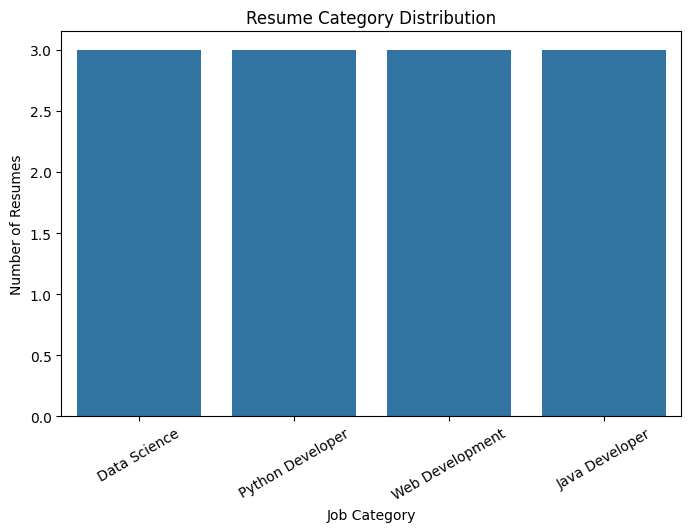

In [8]:
plt.figure(figsize=(8,5))

sns.countplot(x='Category', data=data)

plt.xticks(rotation=30)
plt.title("Resume Category Distribution")
plt.xlabel("Job Category")
plt.ylabel("Number of Resumes")

plt.show()

In [9]:
X = data['Resume']
Y = data['Category']

print("Input:")
print(X.head())

print("\nOutput:")
print(Y.head())

Input:
0    Python machine learning pandas numpy data anal...
1        Python developer Django Flask API programming
2     Machine learning deep learning Python TensorFlow
3    HTML CSS JavaScript React frontend web develop...
4          Web developer HTML CSS JavaScript Bootstrap
Name: Resume, dtype: object

Output:
0        Data Science
1    Python Developer
2        Data Science
3     Web Development
4     Web Development
Name: Category, dtype: object


In [10]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(data['Resume'])

print("TF-IDF conversion completed")
print("Feature Shape:", X.shape)

TF-IDF conversion completed
Feature Shape: (12, 36)


In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.25,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (9, 36)
Testing Data: (3, 36)


In [12]:
model = SVC(
    kernel='linear',
    random_state=42
)

model.fit(X_train, Y_train)

print("Model Training Completed")

Model Training Completed


In [13]:
Y_pred = model.predict(X_test)

print("Prediction Completed")

Prediction Completed


In [14]:
accuracy = accuracy_score(Y_test, Y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.6666666666666666
Accuracy Percentage: 66.66666666666666 %


In [15]:
print(classification_report(Y_test, Y_pred, zero_division=0))

                  precision    recall  f1-score   support

    Data Science       1.00      1.00      1.00         1
Python Developer       1.00      0.50      0.67         2
 Web Development       0.00      0.00      0.00         0

        accuracy                           0.67         3
       macro avg       0.67      0.50      0.56         3
    weighted avg       1.00      0.67      0.78         3



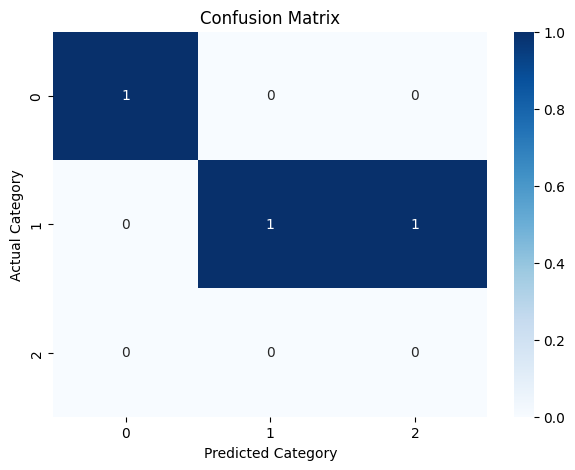

In [16]:
cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

In [17]:
new_resume = """
Python developer with experience in Django, Flask,
REST API, Python programming and SQL
"""

resume_vector = vectorizer.transform([new_resume])

prediction = model.predict(resume_vector)

print("Predicted Resume Category:", prediction[0])

Predicted Resume Category: Python Developer


In [18]:
def screen_resume(resume):
    
    resume_vector = vectorizer.transform([resume])
    
    prediction = model.predict(resume_vector)
    
    print("Resume Screening Result")
    print("-----------------------")
    print("Predicted Category:", prediction[0])

In [20]:
resume = input("Enter Resume Skills / Description: ")

screen_resume(resume)

Enter Resume Skills / Description:  I know HTML CSS JavaScript React and frontend development


Resume Screening Result
-----------------------
Predicted Category: Web Development


In [21]:
resume = input("Enter Resume Skills / Description: ")

screen_resume(resume)

Enter Resume Skills / Description:  Machine learning Python pandas numpy TensorFlow


Resume Screening Result
-----------------------
Predicted Category: Data Science
